In [1]:
import os
import sys

# necessary to make functions available
# Jupyter server should be running from src/python
sys.path.append(
    os.getcwd()
)

In [2]:
import os

import polars as pl

import synapseclient

from plots_for_gsea_and_limma_results import plot_sig_up_down_pathway_counts

In [3]:
# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

GSEA_RESULTS_SYNID = "syn78432275"

In [4]:
os.makedirs(FIGURE_DIR, exist_ok=True)

In [5]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.15.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.15.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [6]:
results = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)

results

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_40724/3570276949.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  results = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)



[syn78432275:gsea_results.parquet]: Found existing file at /Users/dylan.ross/.synapseCache/383/178910383/gsea_results.parquet, skipping download.


Contrast,OmicsType,GeneSet,Term,NES,FDR q-val,Gene %,Tag %,leading_edge_size,gene_set_size,Lead_genes
str,str,str,str,f64,f64,f64,f64,i64,i64,str
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""MSigDB_Hallmark_2020""","""Myc Targets V1""",2.054229,0.0,23.99,57.731959,112,194,"""CDC45;PA2G4;RPS2;SRPK1;UBE2E1;…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Staphylococcus aureus infectio…",-3.573441,0.0,4.72,44.444444,20,45,"""FPR1;KRT9;KRT10;HLA-DMB;HLA-DM…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Graft-versus-host disease""",-2.616281,0.0,15.57,85.714286,18,21,"""HLA-DMB;HLA-DMA;HLA-G;HLA-DQA1…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Asthma""",-1.911691,0.003322,15.0,81.25,13,16,"""HLA-DMB;HLA-DMA;HLA-DQA1;HLA-D…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Dilated cardiomyopathy""",1.868212,0.023344,19.08,55.555556,15,27,"""ITGA2;ITGA2B;TGFB1;ITGB3;ATP2A…"
…,…,…,…,…,…,…,…,…,…,…
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""Sema4D In Semaphorin Signaling…",-1.62075,0.03726,17.78,50.0,9,18,"""MYH11;MYH10;MYH14;RRAS;MYL6;AR…"
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""Fanconi Anemia Pathway R-HSA-6…",-1.619351,0.037489,18.84,52.941176,9,17,"""USP1;CENPX;EME1;UBE2T;FANCD2;F…"
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""RND2 GTPase Cycle R-HSA-969627…",-1.618669,0.037307,23.09,40.909091,9,22,"""PLXND1;CKAP4;ARHGAP5;GOLGA3;TF…"


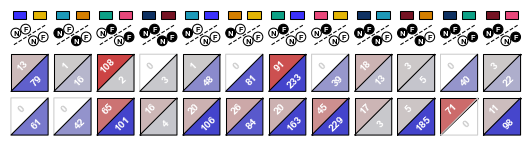

In [7]:
plot_sig_up_down_pathway_counts(
    results,
    os.path.join(FIGURE_DIR, "gsea_sig_pathway_counts.png")
)